In [11]:
import sys
print("Halo dari notebook!")
print("Versi Python:", sys.version)
print("Lokasi Python:", sys.executable)

Halo dari notebook!
Versi Python: 3.13.5 (tags/v3.13.5:6cb20a2, Jun 11 2025, 16:15:46) [MSC v.1943 64 bit (AMD64)]
Lokasi Python: c:\Users\Muhamad Ramdani\AppData\Local\Programs\Python\Python313\python.exe


In [12]:
from pathlib import Path

image_path = Path("images/foto-berdua.jpg")

print("Folder kerja notebook :", Path.cwd())
print("Path gambar           :", image_path)
print("File ditemukan?       :", image_path.exists())

Folder kerja notebook : c:\Project\citra-digital
Path gambar           : images\foto-berdua.jpg
File ditemukan?       : False


Ukuran gambar: (4000, 3000, 3)


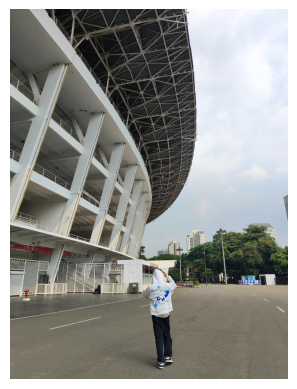

In [14]:
from PIL import Image
import numpy as np

img = Image.open("images/foto-dani.jpg").convert("RGB")
arr = np.array(img)

print("Ukuran gambar:", arr.shape)

import matplotlib.pyplot as plt
plt.imshow(arr)
plt.axis("off")
plt.show()

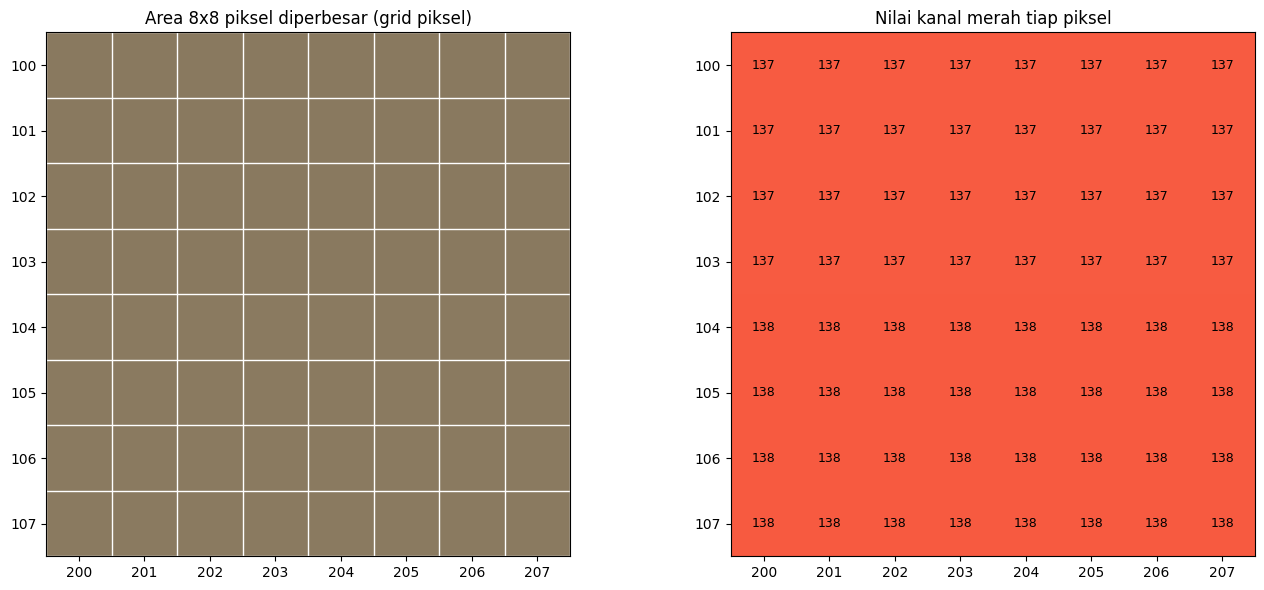

Piksel terpilih (baris 103, kolom 205) -> RGB: [137 121  95]


In [ ]:
y0, x0 = 100, 200
ukuran = 8
crop = arr[y0:y0+ukuran, x0:x0+ukuran]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Kiri: area diperbesar dengan grid piksel
axes[0].imshow(crop, interpolation="nearest")
axes[0].set_title(f"Area {ukuran}x{ukuran} piksel diperbesar (grid piksel)")
axes[0].set_xticks(np.arange(-0.5, ukuran, 1), minor=True)
axes[0].set_yticks(np.arange(-0.5, ukuran, 1), minor=True)
axes[0].grid(which="minor", color="white", linewidth=1)
axes[0].tick_params(which="minor", length=0)
axes[0].set_xticks(range(ukuran))
axes[0].set_yticks(range(ukuran))
axes[0].set_xticklabels(range(x0, x0+ukuran))
axes[0].set_yticklabels(range(y0, y0+ukuran))

# Kanan: nilai kanal MERAH ditulis di tiap kotak
merah = crop[:, :, 0]
axes[1].imshow(merah, cmap="Reds", interpolation="nearest", vmin=0, vmax=255)
axes[1].set_title("Nilai kanal merah tiap piksel")
for i in range(ukuran):
    for j in range(ukuran):
        axes[1].text(j, i, merah[i, j], ha="center", va="center", fontsize=9)
axes[1].set_xticks(range(ukuran))
axes[1].set_yticks(range(ukuran))
axes[1].set_xticklabels(range(x0, x0+ukuran))
axes[1].set_yticklabels(range(y0, y0+ukuran))

plt.tight_layout()
plt.show()

# Pembacaan RGB satu piksel terpilih di dalam area
py, px = 103, 205
print(f"Piksel terpilih (baris {py}, kolom {px}) -> RGB:", arr[py, px])

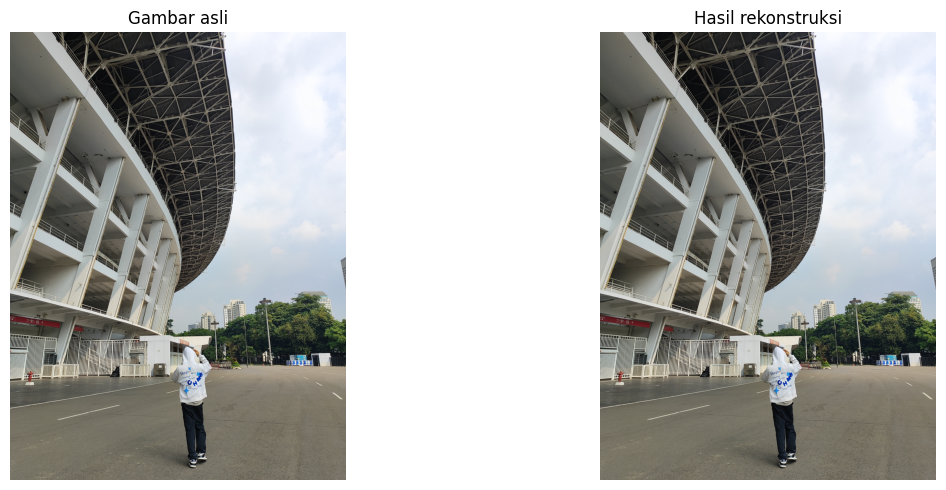

Shape asli        : (4000, 3000, 3)
Shape rekonstruksi: (4000, 3000, 3)
Dtype asli        : uint8
Dtype rekonstruksi: uint8
Array identik?    : True
Selisih maksimum  : 0
Jumlah elemen berbeda: 0


In [15]:
# Bangun array kosong, lalu isi per kanal dari array asli
tinggi, lebar, kanal = arr.shape
rekon_arr = np.zeros((tinggi, lebar, kanal), dtype=np.uint8)
rekon_arr[:, :, 0] = arr[:, :, 0]   # kanal merah
rekon_arr[:, :, 1] = arr[:, :, 1]   # kanal hijau
rekon_arr[:, :, 2] = arr[:, :, 2]   # kanal biru

# Ubah array kembali menjadi gambar
rekon_img = Image.fromarray(rekon_arr)

# Tampilkan berdampingan
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(arr)
axes[0].set_title("Gambar asli")
axes[0].axis("off")
axes[1].imshow(rekon_img)
axes[1].set_title("Hasil rekonstruksi")
axes[1].axis("off")
plt.tight_layout()
plt.show()

# Perbandingan numerik
selisih = np.abs(arr.astype(np.int16) - rekon_arr.astype(np.int16))
print("Shape asli        :", arr.shape)
print("Shape rekonstruksi:", rekon_arr.shape)
print("Dtype asli        :", arr.dtype)
print("Dtype rekonstruksi:", rekon_arr.dtype)
print("Array identik?    :", np.array_equal(arr, rekon_arr))
print("Selisih maksimum  :", selisih.max())
print("Jumlah elemen berbeda:", np.count_nonzero(selisih))

In [ ]:
import os

# Contoh ilustratif 100 x 100
t0, l0, k0 = 100, 100, 3
print("=== Contoh ilustratif 100 x 100 RGB ===")
print("Jumlah piksel      :", t0 * l0)
print("Jumlah nilai kanal :", t0 * l0 * k0)
print("Ukuran mentah      :", t0 * l0 * k0, "byte =", round(t0 * l0 * k0 / 1024, 2), "KB")

# Gambar milikmu
tinggi, lebar, kanal = arr.shape
jumlah_piksel = tinggi * lebar
jumlah_nilai = jumlah_piksel * kanal
bit_per_kanal = arr.dtype.itemsize * 8
ukuran_mentah = jumlah_nilai * (bit_per_kanal // 8)
ukuran_file = os.path.getsize(image_path)

print("\n=== Gambar milikmu ===")
print("Dimensi            :", lebar, "x", tinggi, "piksel")
print("Jumlah piksel      :", jumlah_piksel)
print("Jumlah nilai kanal :", jumlah_nilai)
print("Bit per kanal      :", bit_per_kanal)
print("Nilai berbeda/kanal:", 2 ** bit_per_kanal)
print("Ukuran data mentah :", ukuran_mentah, "byte =", round(ukuran_mentah / 1024, 2), "KB")
print("Ukuran file JPEG   :", ukuran_file, "byte =", round(ukuran_file / 1024, 2), "KB")
print("Rasio mentah/file  :", round(ukuran_mentah / ukuran_file, 2), "kali")

=== Contoh ilustratif 100 x 100 RGB ===
Jumlah piksel      : 10000
Jumlah nilai kanal : 30000
Ukuran mentah      : 30000 byte = 29.3 KB

=== Gambar milikmu ===
Dimensi            : 1280 x 720 piksel
Jumlah piksel      : 921600
Jumlah nilai kanal : 2764800
Bit per kanal      : 8
Nilai berbeda/kanal: 256
Ukuran data mentah : 2764800 byte = 2700.0 KB
Ukuran file JPEG   : 48613 byte = 47.47 KB
Rasio mentah/file  : 56.87 kali


In [ ]:

from PIL import Image
from PIL.ExifTags import TAGS, GPSTAGS

# Lokasi foto
path = "images/foto-dani.jpg"

# Membaca metadata EXIF
img = Image.open(path)
exif = img.getexif()

data_exif = {}

for tag_id, value in exif.items():
    nama_tag = TAGS.get(tag_id, tag_id)

    # Membaca metadata EXIF tambahan
    if nama_tag == "ExifOffset":
        try:
            sub_exif = exif.get_ifd(tag_id)
            for sub_id, sub_value in sub_exif.items():
                sub_name = TAGS.get(sub_id, sub_id)
                data_exif[sub_name] = sub_value
        except Exception:
            pass

    data_exif[nama_tag] = value

# Menampilkan semua tag EXIF
print("Jumlah tag EXIF:", len(data_exif))
print()

for name, value in data_exif.items():
    print(f"{name:28}: {str(value)[:80]}")

# Memeriksa GPS
try:
    gps = exif.get_ifd(34853)
    print("\nData GPS:")
    if gps:
        for tag_id, value in gps.items():
            print(f"{GPSTAGS.get(tag_id, tag_id):28}: {value}")
    else:
        print("Data GPS tidak ditemukan")
except Exception:
    print("\nData GPS tidak ditemukan")


Jumlah tag EXIF: 50

ImageWidth                  : 3000
                       39424: POCO X5 Pro 5G
ImageLength                 : 4000
                       34970: b'\x00'
ResolutionUnit              : 2
ExifVersion                 : 0220
SceneType                   : b'\x01'
ApertureValue               : 1.83
ColorSpace                  : 1
ExposureBiasValue           : 0.0
MaxApertureValue            : 1.83
ExifImageHeight             : 4000
BrightnessValue             : 6.92
DateTimeOriginal            : 2026:06:20 13:49:28
FlashPixVersion             : b'0100'
WhiteBalance                : 0
ExifInteroperabilityOffset  : 6119
Flash                       : 16
ExifImageWidth              : 3000
ComponentsConfiguration     : b'\x01\x02\x03\x00'
MeteringMode                : 2
OffsetTime                  : +07:00
SubsecTimeOriginal          : 796
SubsecTime                  : 796
SubsecTimeDigitized         : 796
OffsetTimeOriginal          : +07:00
DateTimeDigitized           : 2026

In [ ]:
from PIL import Image
from PIL.ExifTags import TAGS, GPSTAGS

path = "images/foto-dani.jpg"

img = Image.open(path)
exif = img.getexif()

print("Jumlah tag EXIF:", len(exif))

gps_tag_id = next(
    (tag_id for tag_id, name in TAGS.items()
     if name == "GPSInfo"),
    None
)

if gps_tag_id is not None and gps_tag_id in exif:
    gps = exif.get_ifd(gps_tag_id)
    for key, value in gps.items():
        print(GPSTAGS.get(key, key), ":", value)
else:
    print("Data GPS tidak ditemukan dalam EXIF.")

Jumlah tag EXIF: 14
Data GPS tidak ditemukan dalam EXIF.
